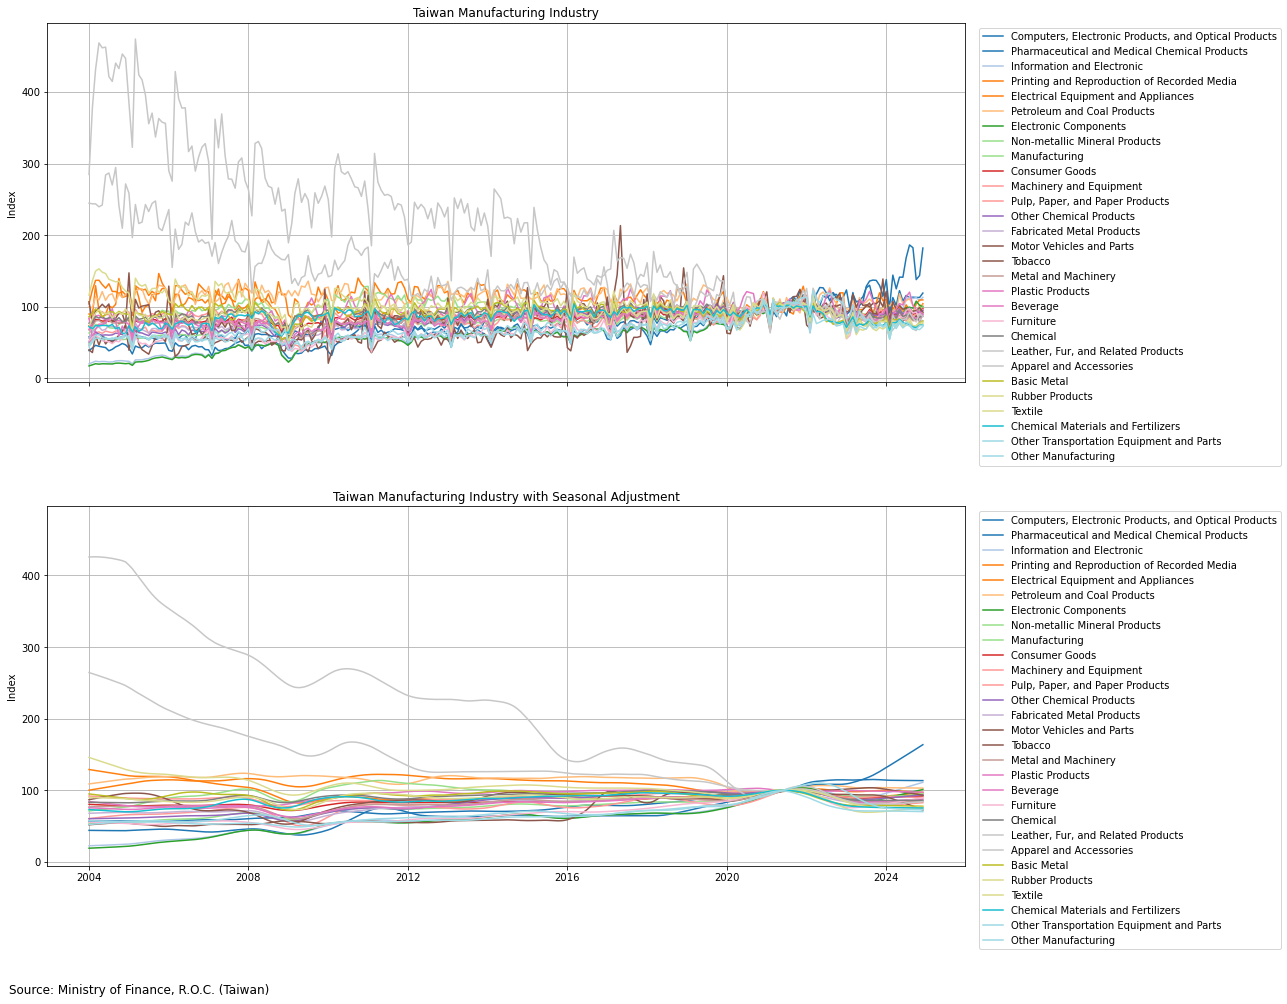

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
from statsmodels.tsa.seasonal import STL
from matplotlib.ticker import FuncFormatter

file_path = "Manufacturing Industry.xlsx"
df = pd.read_excel(file_path)
df.rename(columns={df.columns[0]: "Date"}, inplace=True)
df["Year"] = df["Date"].str.extract(r'(\d+)年')[0]
df["Month"] = df["Date"].str.extract(r'(\d+)月')[0]
df = df.dropna(subset=["Year", "Month"])
df["Year"] = df["Year"].astype(int) + 1911
df["Month"] = df["Month"].astype(int)
df["Date"] = pd.to_datetime(df[["Year", "Month"]].assign(day=1))
df.drop(columns=["Year", "Month"], inplace=True)

cols = ["Manufacturing", "Metal and Machinery", "Basic Metal", "Fabricated Metal Products", "Electrical Equipment and Appliances",
        "Machinery and Equipment", "Motor Vehicles and Parts", "Other Transportation Equipment and Parts","Information and Electronic",
        "Electronic Components", "Computers, Electronic Products, and Optical Products", "Chemical", "Leather, Fur, and Related Products",
        "Pulp, Paper, and Paper Products", "Printing and Reproduction of Recorded Media", "Petroleum and Coal Products", "Chemical Materials and Fertilizers", 
        "Other Chemical Products", "Pharmaceutical and Medical Chemical Products", "Rubber Products", "Plastic Products", "Consumer Goods",
        "Beverage", "Tobacco", "Textile", "Apparel and Accessories", "Non-metallic Mineral Products", "Furniture", "Other Manufacturing"]

latest_values = df[df["Date"].dt.year == 2024].iloc[-1][cols]
sorted_cols = latest_values.sort_values(ascending=False).index.tolist()

colors = cm.get_cmap('tab20', len(sorted_cols))
fig, axes = plt.subplots(2, 1, figsize=(18, 14), sharex=True, sharey=True)

for i, col in enumerate(sorted_cols):
    axes[0].plot(df["Date"], df[col], label=col, color=colors(i))
axes[0].set_title("Taiwan Manufacturing Industry")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[0].grid(True)
axes[0].set_ylabel("Index")

for i, col in enumerate(sorted_cols):
    ts = pd.Series(df[col].values, index=df["Date"]).asfreq("MS")
    try:
        trend = STL(ts, period=12).fit().trend
        axes[1].plot(trend, label=col, color=colors(i))
    except Exception as e:
        print(f"跳過：{col}，原因：{e}")
axes[1].set_title("Taiwan Manufacturing Industry with Seasonal Adjustment")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[1].grid(True)
axes[1].set_ylabel("Index")

formatter = FuncFormatter(lambda x, _: f"{x:,.0f}")
for ax in axes:
    ax.yaxis.set_major_formatter(formatter)
plt.figtext(0.01, 0.01, "Source: Ministry of Finance, R.O.C. (Taiwan)", ha='left', fontsize=12)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

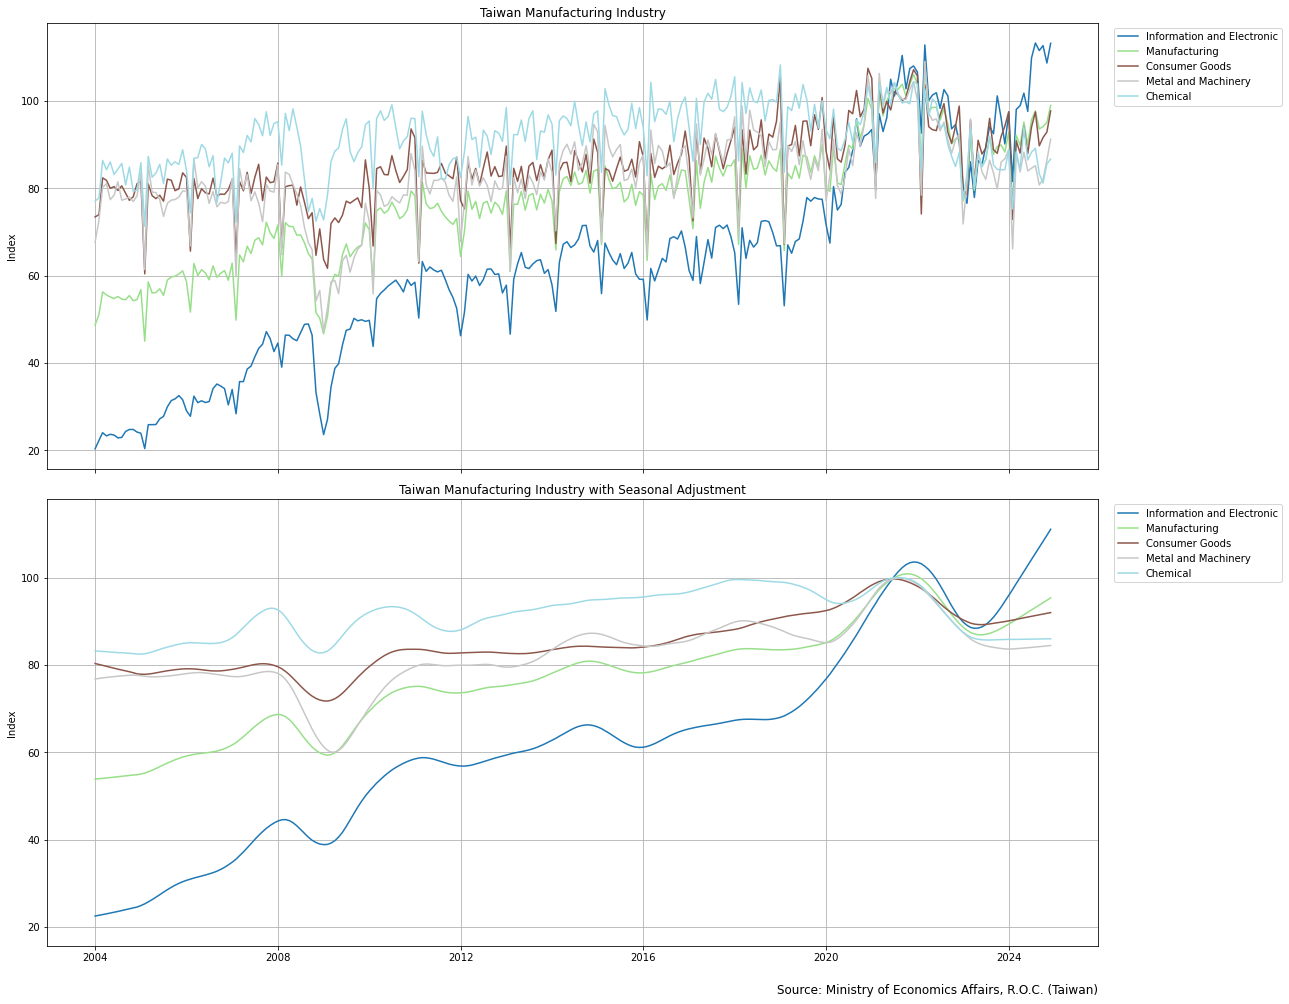

In [2]:
cols = ["Manufacturing", "Metal and Machinery", "Information and Electronic", "Chemical", "Consumer Goods"]
latest_values = df[df["Date"].dt.year == 2024].iloc[-1][cols]
sorted_cols = latest_values.sort_values(ascending=False).index.tolist()

colors = cm.get_cmap('tab20', len(sorted_cols))
fig, axes = plt.subplots(2, 1, figsize=(18, 14), sharex=True, sharey=True)

for i, col in enumerate(sorted_cols):
    axes[0].plot(df["Date"], df[col], label=col, color=colors(i))
axes[0].set_title("Taiwan Manufacturing Industry")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[0].grid(True)
axes[0].set_ylabel("Index")

for i, col in enumerate(sorted_cols):
    ts = pd.Series(df[col].values, index=df["Date"]).asfreq("MS")
    try:
        trend = STL(ts, period=12).fit().trend
        axes[1].plot(trend, label=col, color=colors(i))
    except Exception as e:
        print(f"跳過：{col}，原因：{e}")
axes[1].set_title("Taiwan Manufacturing Industry with Seasonal Adjustment")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
axes[1].grid(True)
axes[1].set_ylabel("Index")

formatter = FuncFormatter(lambda x, _: f"{x:,.0f}")
for ax in axes:
    ax.yaxis.set_major_formatter(formatter)
plt.figtext(0.01, 0.01, "Source: National Statistics, R.O.C. (Taiwan)", ha='left', fontsize=12)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()